# **3. Khai Thác Đặc Trưng**

Toàn bộ code tạo đặc trưng nằm trong **`features.py`**, để notebook và web demo dùng **chung một đoạn code**. Nếu hai nơi viết hai kiểu, kết quả sẽ sai mà không báo lỗi. Notebook này gọi các hàm đó, giải thích và kiểm tra kết quả.

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error

import features as F

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
PROCESSED_DIR = Path('data/processed')

def save_fig(name):
    """Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)

with open(PROCESSED_DIR / 'config.json', encoding='utf-8') as f:
    cfg = {k: pd.Timestamp(v) for k, v in json.load(f).items()}
TRAIN_END, VALID_END = cfg['TRAIN_END'], cfg['VALID_END']

full = pd.read_parquet(PROCESSED_DIR / 'rossmann_full.parquet')
print(full.shape)

(1103850, 19)


**3.1 Đặc trưng thường (giống đồ án 1)**

`F.add_features` tạo lại các đặc trưng đã chọn ở đồ án 1:

| Nhóm | Đặc trưng |
|---|---|
| Lịch | `DayOfWeek`, `Day`, `Month` |
| Đối thủ | `CompetitionDistance`, `CompetitorLongevity` (số tháng đối thủ đã mở) |
| Khuyến mãi | `Promo`, `PromoPrev`, `PromoNext`, `PromoRun` (ngày KM thứ mấy), `LastPromo`, `Promo2`, `Promo2SinceWeek`, `Promo2_Active` |
| Ngày lễ | `DaysSinceHoliday`, `DaystoHoliday` |

Một điểm **sửa so với đồ án 1**: `PromoPrev` / `PromoNext` được tính **trong từng cửa hàng** (`groupby('Store').shift`). Đồ án 1 shift trên toàn bảng, nên ngày đầu tiên của một cửa hàng lấy nhầm `Promo` của cửa hàng đứng trước.

In [2]:
full = F.add_features(full)
full.loc[(full['Store'] == 1) & full['Date'].between('2015-07-24', '2015-07-31'),
         ['Date', 'DayOfWeek', 'Open', 'Promo', 'PromoPrev', 'PromoNext', 'PromoRun', 'LastPromo',
          'DaysSinceHoliday', 'DaystoHoliday']]

,Date,DayOfWeek,Open,Promo,PromoPrev,PromoNext,PromoRun,LastPromo,DaysSinceHoliday,DaystoHoliday
934,2015-07-24,5,1,0,0,0,0,7.0,50.0,30.0
935,2015-07-25,6,1,0,0,0,0,8.0,51.0,30.0
936,2015-07-26,7,0,0,0,1,0,9.0,52.0,30.0
937,2015-07-27,1,1,1,0,1,1,0.0,53.0,30.0
938,2015-07-28,2,1,1,1,1,2,0.0,54.0,30.0
939,2015-07-29,3,1,1,1,1,3,0.0,55.0,30.0
940,2015-07-30,4,1,1,1,1,4,0.0,56.0,30.0
941,2015-07-31,5,1,1,1,0,5,0.0,57.0,30.0


**3.2 Đặc trưng độ trễ theo horizon**

Quy tắc quan trọng nhất của đồ án: **độ trễ nhỏ nhất phải ≥ horizon**. Khi đó mọi độ trễ lúc dự báo đều là **giá trị thật đã biết**, không phải dùng dự đoán của chính mô hình (không cần dự báo cuốn chiếu).

| Mô hình | Dùng để | Độ trễ |
|---|---|---|
| h = 1 | Dự báo ngày mai | lag 1, 2, 7, 14 |
| h = 7 | Dự báo cả tuần tới | lag 7, 14, 21, 28 |

Mỗi horizon có thêm 3 đặc trưng tổng hợp, đều tính từ những ngày ≤ t − h:
- `roll7`, `roll28`: trung bình 7 / 28 ngày gần nhất.
- `dow_mean4`: trung bình cùng thứ của 4 tuần trước.
- `same_promo`: giá trị của ngày **cùng thứ, cùng trạng thái khuyến mãi** gần nhất trong 4 tuần trước (vì khuyến mãi chạy xen kẽ từng tuần, xem notebook 2 mục 2.6).

Độ trễ được tạo cho **cả** `Sales` và `Customers`: số khách hôm qua giúp đoán doanh thu hôm nay và ngược lại. Mô hình **không** dùng giá trị cùng ngày của đại lượng kia. Ngày đóng cửa được coi là NaN, không phải 0.

In [3]:
data = {h: F.add_lag_features(full, h) for h in F.HORIZONS}
for h in F.HORIZONS:
    print(f'h = {h}: {len(F.lag_columns(h))} cột độ trễ ->', F.lag_columns(h)[:8], '...')

h = 1: 16 cột độ trễ -> ['Customers_lag_1', 'Customers_lag_2', 'Customers_lag_7', 'Customers_lag_14', 'Customers_roll7', 'Customers_roll28', 'Customers_dow_mean4', 'Customers_same_promo'] ...
h = 7: 16 cột độ trễ -> ['Customers_lag_7', 'Customers_lag_14', 'Customers_lag_21', 'Customers_lag_28', 'Customers_roll7', 'Customers_roll28', 'Customers_dow_mean4', 'Customers_same_promo'] ...


Kiểm tra trên cửa hàng 1: `Customers_lag_1` của ngày 21/07 phải bằng số khách ngày 20/07, còn ngày Chủ nhật đóng cửa thì độ trễ là NaN.

In [4]:
data[1].loc[(data[1]['Store'] == 1) & data[1]['Date'].between('2015-07-20', '2015-07-31'),
            ['Date', 'DayOfWeek', 'Promo', 'Customers', 'Customers_lag_1', 'Customers_lag_7',
             'Customers_same_promo', 'Customers_roll7']]

,Date,DayOfWeek,Promo,Customers,Customers_lag_1,Customers_lag_7,Customers_same_promo,Customers_roll7
930,2015-07-20,1,0,526.0,NaN,553.0,540.0,532.500000
931,2015-07-21,2,0,469.0,526.0,544.0,485.0,528.000000
932,2015-07-22,3,0,463.0,469.0,550.0,485.0,515.500000
933,2015-07-23,4,0,503.0,463.0,517.0,480.0,501.000000
934,2015-07-24,5,0,459.0,503.0,519.0,449.0,498.666667
935,2015-07-25,6,0,500.0,459.0,512.0,512.0,488.666667
936,2015-07-26,7,0,0.0,500.0,NaN,NaN,486.666667
937,2015-07-27,1,1,612.0,NaN,526.0,553.0,486.666667
938,2015-07-28,2,1,560.0,612.0,469.0,544.0,501.000000
939,2015-07-29,3,1,523.0,560.0,463.0,550.0,516.166667


**3.3 Tỷ lệ thiếu của các đặc trưng độ trễ**

In [5]:
tables = []
for h in F.HORIZONS:
    cols = [c for c in F.lag_columns(h) if c.startswith('Customers')]      # cột của Sales thiếu giống hệt
    s = data[h].loc[F.is_trainable(data[h]), cols].isna().mean().mul(100).round(1)
    tables.append(pd.DataFrame({f'Đặc trưng (h = {h})': s.index, 'Thiếu (%)': s.values}))
pd.concat(tables, axis=1)

,Đặc trưng (h = 1),Thiếu (%),Đặc trưng (h = 7),Thiếu (%)
0,Customers_lag_1,19.1,Customers_lag_7,4.1
1,Customers_lag_2,19.5,Customers_lag_14,5.3
2,Customers_lag_7,4.1,Customers_lag_21,6.0
3,Customers_lag_14,5.3,Customers_lag_28,6.9
4,Customers_roll7,0.5,Customers_roll7,1.3
5,Customers_roll28,1.6,Customers_roll28,2.3
6,Customers_dow_mean4,0.9,Customers_dow_mean4,0.9
7,Customers_same_promo,2.7,Customers_same_promo,2.7


**Nhận xét:** với h = 1, `lag_1` và `lag_2` thiếu khoảng 19%: thứ Hai đứng sau Chủ nhật đóng cửa nên `lag_1` là NaN, tương tự thứ Ba với `lag_2`. Đây là thiếu **có ý nghĩa** (hôm qua đóng cửa), không phải lỗi dữ liệu, và LightGBM tự học cách xử lý NaN. Các đặc trưng tổng hợp (`roll7`, `dow_mean4`, `same_promo`) gần như luôn có giá trị (thiếu dưới 3%), nên vẫn bù được khi một độ trễ đơn lẻ bị thiếu.

**3.4 Thí nghiệm: độ trễ ngắn giúp được bao nhiêu?**

So sánh 3 bộ đặc trưng trên tập kiểm định, với cùng tham số LightGBM:
1. **Không có độ trễ**: chỉ đặc trưng thường.
2. **Độ trễ h = 7**: thêm độ trễ dùng được khi dự báo cả tuần.
3. **Độ trễ h = 1**: thêm độ trễ dùng được khi dự báo ngày mai.

`learning_rate = 0.2` để chạy nhanh. Thí nghiệm này chỉ để so sánh, notebook 4 mới huấn luyện kỹ.

In [6]:
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0                      # tránh chia cho 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

def quick_experiment(d, cols, target):
    """Huấn luyện nhanh trên train, đánh giá trên valid. Trả về RMSPE, MAE (đơn vị thật)."""
    d = d[F.is_trainable(d)]
    tr = d[d['Date'] <= TRAIN_END]
    va = d[(d['Date'] > TRAIN_END) & (d['Date'] <= VALID_END)]
    model = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.2, num_leaves=127,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              random_state=0, n_jobs=-1, verbose=-1)
    model.fit(tr[cols], np.log1p(tr[target]), eval_X=(va[cols],), eval_y=(np.log1p(va[target]),),
              callbacks=[lgb.early_stopping(50, verbose=False)])
    pred = np.expm1(model.predict(va[cols]))
    return rmspe(va[target], pred), mean_absolute_error(va[target], pred)

settings = {'Không có độ trễ': (data[1], F.BASE_FEATURES),
            'Độ trễ h = 7':    (data[7], F.feature_columns(7)),
            'Độ trễ h = 1':    (data[1], F.feature_columns(1))}
rows = []
t0 = time.time()
for target in F.TARGETS:
    for name, (d, cols) in settings.items():
        r, m = quick_experiment(d, cols, target)
        rows.append({'Mục tiêu': target, 'Bộ đặc trưng': name, 'RMSPE': r, 'MAE': m})
        print(f'{target:<10} {name:<16} RMSPE {r:.4f} | MAE {m:.1f}')
exp = pd.DataFrame(rows)
print(f'Thời gian: {time.time() - t0:.0f}s')

Customers  Không có độ trễ  RMSPE 0.0968 | MAE 56.7


Customers  Độ trễ h = 7     RMSPE 0.0937 | MAE 53.0


Customers  Độ trễ h = 1     RMSPE 0.0855 | MAE 48.3


Sales      Không có độ trễ  RMSPE 0.1226 | MAE 710.2


Sales      Độ trễ h = 7     RMSPE 0.1135 | MAE 607.0


Sales      Độ trễ h = 1     RMSPE 0.1043 | MAE 557.4
Thời gian: 368s


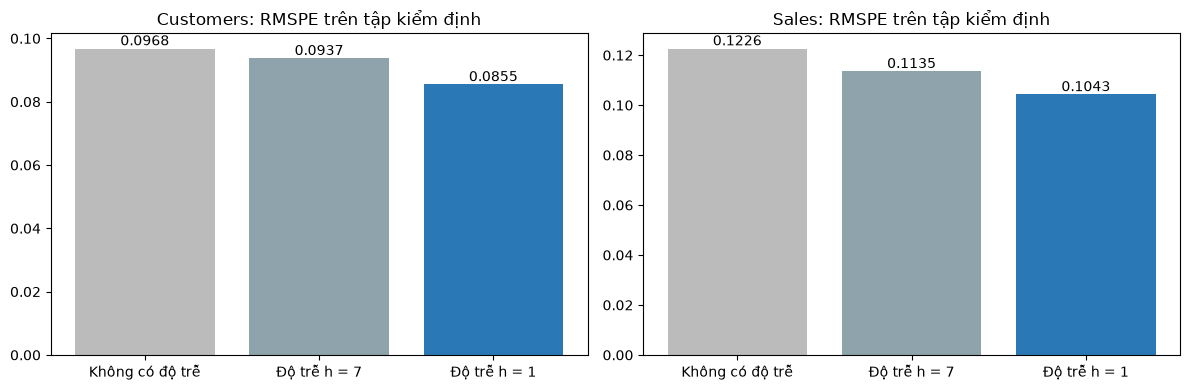

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axes, F.TARGETS):
    part = exp[exp['Mục tiêu'] == target]
    bars = ax.bar(part['Bộ đặc trưng'], part['RMSPE'], color=['#bbbbbb', '#8fa3ad', '#2a78b5'])
    ax.bar_label(bars, fmt='%.4f')
    ax.set_title(f'{target}: RMSPE trên tập kiểm định')
save_fig('experiment_lags')

**Nhận xét:** độ trễ giúp cả hai mục tiêu, và độ trễ càng gần càng tốt.
- Số khách: RMSPE giảm từ 0,0968 (không có độ trễ) xuống 0,0937 với h = 7 (giảm 3%) và 0,0855 với h = 1 (giảm 12%); MAE còn 48,3 khách.
- Doanh thu: RMSPE giảm từ 0,1226 xuống 0,1135 (giảm 7%) và 0,1043 (giảm 15%). Mức giảm 15% với h = 1 khớp với kết quả lag_1, lag_8 ở đồ án 1.

Độ trễ h = 7 giúp số khách ít hơn doanh thu, vì số khách vốn đã dễ đoán từ thứ trong tuần, khuyến mãi và đặc điểm cửa hàng (không có độ trễ đã đạt RMSPE dưới 0,10).

**3.5 Lưu dữ liệu**

Mỗi horizon lưu một file, chỉ gồm các dòng dùng để huấn luyện/đánh giá (mở cửa, có doanh thu) và các cột cần thiết.

In [8]:
keep = ['Date', 'Sales', 'Customers']          # Store đã có trong danh sách đặc trưng
for h in F.HORIZONS:
    d = data[h][F.is_trainable(data[h])]
    d = d[keep + F.feature_columns(h)].reset_index(drop=True)
    d.to_parquet(PROCESSED_DIR / f'dataset_h{h}.parquet', index=False)
    print(f'Đã lưu dataset_h{h}.parquet: {d.shape}')

Đã lưu dataset_h1.parquet: (844338, 37)


Đã lưu dataset_h7.parquet: (844338, 37)


**Nhận xét:** mỗi file có 844.338 dòng và 37 cột: 18 đặc trưng thường, 16 đặc trưng độ trễ, cùng `Date`, `Sales`, `Customers`. Hai file chỉ khác nhau ở các cột độ trễ.